# 確率分布の関係図 — 解説ノートブック

本書（マーケティングサイエンス）で登場する全確率分布を、**分布の種類**・**数式**・**本書での役割**・**他の分布との関係**の観点から整理する。

次の一覧図は、本書に登場する確率分布と、分布間の導出・混合・極限の関係をまとめたものである。

![本書に登場する確率分布の関係図](images/00_probability_distributions_relations.png)

---

## 読み方

分布を離散分布、連続分布、混合・複合モデル、派生・特殊分布に分けて説明する。分布間の導出・混合・極限の関係は第5節の構造図にまとめる。

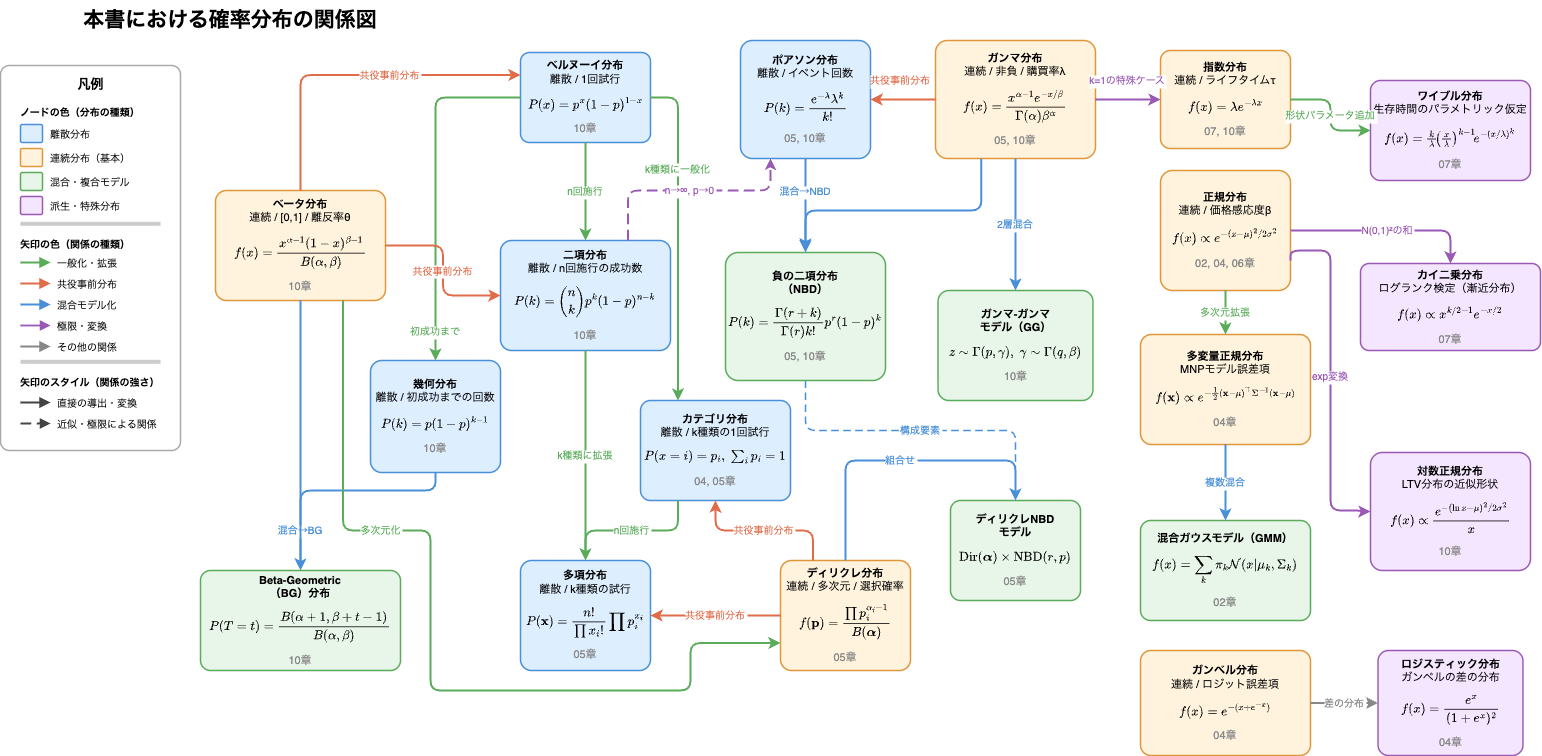

## 全分布一覧

| # | 分布名 | 登場章 | 種類 |
|---|--------|--------|------|
| 1 | ベルヌーイ分布 | 10 | 離散 |
| 2 | 二項分布 | 05, 10 | 離散 |
| 3 | カテゴリ分布 | 04, 05 | 離散 |
| 4 | 多項分布 | 05 | 離散 |
| 5 | 幾何分布 | 10 | 離散 |
| 6 | ポアソン分布 | 05, 10 | 離散 |
| 7 | 負の二項分布 (NBD) | 05, 10 | 混合 |
| 8 | ガンマ分布 | 05, 10 | 連続 |
| 9 | ガンマ・ガンマモデル (GG) | 10 | 混合 |
| 10 | ベータ分布 | 05, 10 | 連続 |
| 11 | Beta-Geometric分布 (BG) | 10 | 混合 |
| 12 | ディリクレ分布 | 05 | 連続 |
| 13 | NBDとディリクレ分布を組み合わせたモデル | 05 | 混合 |
| 14 | 正規分布 | 02, 03, 04, 06, 09 | 連続 |
| 15 | 多変量正規分布 | 04 | 連続 |
| 16 | 混合ガウスモデル (GMM) | 02 | 混合 |
| 17 | ガンベル分布 | 04 | 連続 |
| 18 | ロジスティック分布 | 04 | 派生 |
| 19 | 指数分布 | 05, 07, 10 | 連続 |
| 20 | ワイブル分布 | 07 | 派生 |
| 21 | カイ二乗分布 | 05, 07 | 派生 |
| 22 | 対数正規分布 | —（参考） | 派生 |


In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats

plt.rcParams["font.family"] = "Hiragino Sans"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120

---
## 1. 離散分布群 🔵

ベルヌーイ分布を起点に、**一般化・拡張**（緑の矢印）によって派生する。


### 1-1. ベルヌーイ分布

**数式**
$$P(x) = p^x(1-p)^{1-x}, \quad x \in \{0, 1\}$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $p$ |
| 分散 $\mathrm{Var}[X]$ | $p(1-p)$ |
| 最頻値 | $0\;(p<\tfrac{1}{2})$、$0$ と $1\;(p=\tfrac{1}{2})$、$1\;(p>\tfrac{1}{2})$ |
| エントロピー | $-p\ln p-(1-p)\ln(1-p)$ |

**本書での役割（10章）**
BG/NBDモデルの離反プロセス。各購買直後に確率 $\theta_i$ で離反するという離散試行のモデル化。

**他の分布との関係**
- → **二項分布**：n回試行の成功数（一般化）
- → **カテゴリ分布**：2値 → k種類に一般化
- → **幾何分布**：初めて成功するまでの試行回数
- ← **ベータ分布**：確率パラメータを混合（ベイズ推論では共役事前分布）


### 1-2. 二項分布

**数式**
$$P(k) = \binom{n}{k} p^k (1-p)^{n-k}$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $np$ |
| 分散 $\mathrm{Var}[X]$ | $np(1-p)$ |
| 最頻値 | $0<p<1$ では、$(n+1)p$ が整数でなければ $\lfloor(n+1)p\rfloor$、整数 $m$ なら $m-1$ と $m$。$p=0,1$ ではそれぞれ $0,n$ |
| エントロピー | $\approx \tfrac{1}{2}\ln\bigl(2\pi e\,np(1-p)\bigr)$（大 $n$ 近似）|

**本書での役割（10章）**
n回の独立なベルヌーイ試行で成功がk回起きる確率。BG/NBDの理論的背景。

**他の分布との関係**
- ← **ベルヌーイ分布**：n=1の特殊ケース
- → **多項分布**：k種類に拡張
- → **ポアソン分布**：$n\to\infty,\; p\to 0$（極限、破線）
- ← **ベータ分布**：確率パラメータを混合（ベイズ推論では共役事前分布）


### 1-3. カテゴリ分布

**数式**
$$P(X=i) = p_i, \quad \sum_i p_i = 1, \qquad X_i=\mathbf{1}_{\{X=i\}}$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X_i]$ | $p_i$ |
| 分散 $\mathrm{Var}[X_i]$ | $p_i(1-p_i)$ |
| エントロピー | $H=-\sum_i p_i\ln p_i$ |

**本書での役割（04, 05章）**
1回の試行でk種類のうちいずれかが選ばれる確率分布。ロジットモデル・多項分布の基礎。

**他の分布との関係**
- ← **ベルヌーイ分布**：k=2の特殊ケース
- → **多項分布**：n回試行に拡張
- ← **ディリクレ分布**：選択確率を混合（ベイズ推論では共役事前分布）


### 1-4. 多項分布

**数式**
$$P(\mathbf{x}) = \frac{n!}{\prod_i x_i!} \prod_i p_i^{x_i}$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X_i]$ | $np_i$ |
| 分散 $\mathrm{Var}[X_i]$ | $np_i(1-p_i)$ |
| 共分散 $\mathrm{Cov}[X_i,X_j]\;(i\neq j)$ | $-np_ip_j$ |

**本書での役割（05章）**
各購買機会における複数ブランドからの選択プロセス。ブランド別購買数の条件付き分布。

**他の分布との関係**
- ← **二項分布**：k=2の特殊ケース
- ← **カテゴリ分布**：1回試行→n回試行
- ← **ディリクレ分布**：選択確率を混合（ベイズ推論では共役事前分布）


### 1-5. 幾何分布

**数式**
$$P(k) = p(1-p)^{k-1}$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $1/p$ |
| 分散 $\mathrm{Var}[X]$ | $(1-p)/p^2$ |
| 最頻値 | $1$ |
| エントロピー | $\dfrac{-(1-p)\ln(1-p)-p\ln p}{p}$ |
| 無記憶性 | $P(X>s+t\mid X>s)=P(X>t)$ |

**本書での役割（10章）**
BG/NBDモデルにおいて、$\theta_i$ 所与のとき ちょうどk回目の購買後に離反する確率。BG（Beta-Geometric）の「G」の由来。

**他の分布との関係**
- ← **ベルヌーイ分布**：初成功までの試行数
- → **BG分布**：ベータ分布と混合してBG分布を構成


### 1-6. ポアソン分布

**数式**
$$P(k) = \frac{e^{-\lambda}\lambda^k}{k!}$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $\lambda$ |
| 分散 $\mathrm{Var}[X]$ | $\lambda$（平均＝分散）|
| 最頻値 | $\lambda$ が非整数なら $\lfloor\lambda\rfloor$、正整数なら $\lambda-1$ と $\lambda$、$\lambda=0$ なら $0$ |
| エントロピー | $\approx\tfrac{1}{2}\ln(2\pi e\lambda)$（大 $\lambda$ 近似）|

**本書での役割（05, 10章）**
消費者個人の購買回数のモデル化（一定期間内のランダムイベント回数）。NBD・BG/NBDの購買プロセス層の基礎。

**他の分布との関係**
- ← **二項分布**：$n\to\infty,\; p\to0$ の極限（破線）
- ← **ガンマ分布**：$\lambda$ の個人間混合分布
- → **NBD**：ガンマ分布で混合するとNBDが導出される


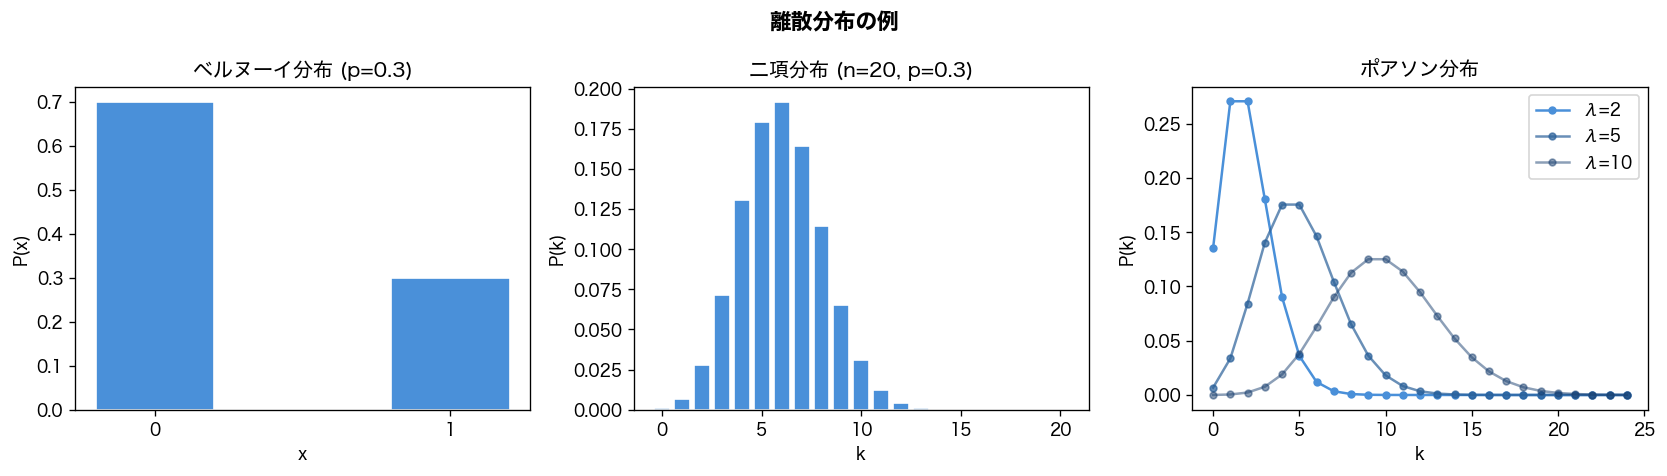

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle("離散分布の例", fontsize=13, fontweight="bold")

# ベルヌーイ分布
p = 0.3
axes[0].bar([0, 1], [1 - p, p], color="#4a90d9", edgecolor="white", width=0.4)
axes[0].set_title("ベルヌーイ分布 (p=0.3)")
axes[0].set_xticks([0, 1])
axes[0].set_xlabel("x")
axes[0].set_ylabel("P(x)")

# 二項分布
n, p_b = 20, 0.3
k_b = np.arange(0, n + 1)
axes[1].bar(
    k_b, stats.binom.pmf(k_b, n, p_b), color="#4a90d9", edgecolor="white"
)
axes[1].set_title(f"二項分布 (n={n}, p={p_b})")
axes[1].set_xlabel("k")
axes[1].set_ylabel("P(k)")

# ポアソン分布
for lam, color, alpha in [
    (2, "#4a90d9", 1.0),
    (5, "#2a6099", 0.7),
    (10, "#1a4070", 0.5),
]:
    k_p = np.arange(0, 25)
    axes[2].plot(
        k_p,
        stats.poisson.pmf(k_p, lam),
        "o-",
        label=f"λ={lam}",
        color=color,
        alpha=alpha,
        markersize=4,
    )
axes[2].set_title("ポアソン分布")
axes[2].set_xlabel("k")
axes[2].set_ylabel("P(k)")
axes[2].legend()

plt.tight_layout()
plt.show()

---
## 2. 連続分布（基本）群 🟠

確率モデルの観測分布、個人間異質性を表す混合分布、ベイズ推定の事前分布などとして利用される。


### 2-1. ガンマ分布

**数式**
$$f(x) = \frac{x^{\alpha-1}e^{-x/\beta}}{\Gamma(\alpha)\beta^\alpha}, \quad x > 0$$

**統計量**（形状 $\alpha$、スケール $\beta$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $\alpha\beta$ |
| 分散 $\mathrm{Var}[X]$ | $\alpha\beta^2$ |
| 最頻値 | $(\alpha-1)\beta\quad(\alpha\ge1)$ |
| 変動係数 | $1/\sqrt{\alpha}$ |
| 微分エントロピー | $\alpha+\ln\beta+\ln\Gamma(\alpha)+(1-\alpha)\psi(\alpha)$ |

$\psi$ はディガンマ関数。

**本書での役割（05, 10章）**
① 消費者間の購買率 $\lambda_i$ の異質性を表す混合分布 → NBDを導出
② Pareto/NBDでの離反レート $\mu_i$ の異質性
③ ガンマ・ガンマモデルでの購買金額の個人内・個人間ばらつき

**他の分布との関係**
- → **ポアソン分布**：混合するとNBDを構成する。ベイズ推論では $\lambda$ の共役事前分布でもある
- → **NBD**：ポアソン-ガンマ混合
- → **ガンマ・ガンマモデル**：2層混合
- → **指数分布**：$\alpha=1$（k=1の特殊ケース）


### 2-2. ベータ分布

**数式**
$$f(x) = \frac{x^{\alpha-1}(1-x)^{\beta-1}}{B(\alpha,\beta)}, \quad x \in [0,1]$$

**統計量**（$\alpha_0=\alpha+\beta$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $\dfrac{\alpha}{\alpha_0}$ |
| 分散 $\mathrm{Var}[X]$ | $\dfrac{\alpha\beta}{\alpha_0^2(\alpha_0+1)}$ |
| 最頻値 | $\dfrac{\alpha-1}{\alpha_0-2}\quad(\alpha,\beta>1)$ |
| 集中度 | $\alpha_0$ が大きいほど平均 $\alpha/\alpha_0$ に集中 |

**本書での役割（05, 10章）**
第5章ではディリクレ分布の周辺分布としてブランド選択確率を表し、第10章ではBG/NBDモデルの離反確率 $\theta_i$ の消費者間異質性を表す。

**他の分布との関係**
- → **ベルヌーイ分布**：共役事前分布（$\theta$）
- → **二項分布**：共役事前分布
- → **BG分布**：幾何分布と混合してBG分布を構成


### 2-3. ディリクレ分布

**数式**
$$f(\mathbf{p}) = \frac{\prod_i p_i^{\alpha_i-1}}{B(\boldsymbol{\alpha})}, \quad p_i > 0,\; \sum_i p_i = 1$$

**統計量**（$\alpha_0=\sum_i\alpha_i$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[p_i]$ | $\alpha_i/\alpha_0$ |
| 分散 $\mathrm{Var}[p_i]$ | $\dfrac{\alpha_i(\alpha_0-\alpha_i)}{\alpha_0^2(\alpha_0+1)}$ |
| 共分散 $\mathrm{Cov}[p_i,p_j]\;(i\neq j)$ | $-\dfrac{\alpha_i\alpha_j}{\alpha_0^2(\alpha_0+1)}$ |
| 集中度 | $\alpha_0$ が大きいほど $p_i\approx\alpha_i/\alpha_0$ に集中 |

**本書での役割（05章）**
消費者ごとのブランド選択確率ベクトル $\mathbf{p}_i$ の異質性を表す混合分布。NBDとディリクレ分布を組み合わせたモデルの核であり、ベイズ推論では多項分布の共役事前分布でもある。

**他の分布との関係**
- → **多項分布**：共役事前分布
- → **カテゴリ分布**：共役事前分布
- → **NBDとディリクレ分布を組み合わせたモデル**：NBDと組み合わせ


### 2-4. 正規分布（ガウス分布）

**数式**
$$f(x) = \frac{1}{\sqrt{2\pi}\,\sigma}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right], \quad \sigma>0$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $\mu$ |
| 分散 $\mathrm{Var}[X]$ | $\sigma^2$ |
| 最頻値・中央値 | $\mu$ |
| 微分エントロピー | $\tfrac{1}{2}\ln(2\pi e\sigma^2)$ |
| **最大エントロピー性** | 同じ平均・分散をもつ分布の中で最大エントロピー |

**本書での役割（02, 03, 04, 06, 09章）**
① GMMによる顧客セグメンテーション
② プロビットモデルの誤差項仮定（標準正規）
③ 階層ベイズでの価格感応度 $\beta_i$ の事前分布
④ 状態空間モデルでの参照（Box-Cox変換の近似目標）

**他の分布との関係**
- → **多変量正規分布**：多次元拡張
- → **カイ二乗分布**：独立な標準正規変数の二乗和


### 2-5. ガンベル分布

**数式**
$$f(x) = e^{-(x+e^{-x})}$$

**統計量**（位置 $0$、スケール $1$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $\gamma\approx0.5772$（オイラー–マスケローニ定数）|
| 分散 $\mathrm{Var}[X]$ | $\pi^2/6\approx1.645$ |
| 最頻値 | $0$ |
| 微分エントロピー | $\gamma+1\approx1.5772$ |

**本書での役割（04章）**
ロジットモデルの誤差項仮定（極値分布・2重指数分布）。差がロジスティック分布になり選択確率の閉形式解（ソフトマックス形式）を導出。

**他の分布との関係**
- → **ロジスティック分布**：2つのガンベル分布の差の分布


### 2-6. 指数分布

**数式**
$$f(x) = \lambda e^{-\lambda x}, \quad x \geq 0$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $1/\lambda$ |
| 分散 $\mathrm{Var}[X]$ | $1/\lambda^2$ |
| 最頻値 | $0$ |
| 微分エントロピー | $1-\ln\lambda$ |
| **無記憶性** | $P(X>s+t\mid X>s)=P(X>t)$ |

**本書での役割（05, 07, 10章）**
① Pareto/NBDモデルでの顧客ライフタイム $\tau_i$（連続時間の離反プロセス）
② 生存時間解析で仮定する分布形の代表例

**他の分布との関係**
- ← **ガンマ分布**：$\alpha=1$の特殊ケース
- → **ワイブル分布**：形状パラメータkを追加して一般化


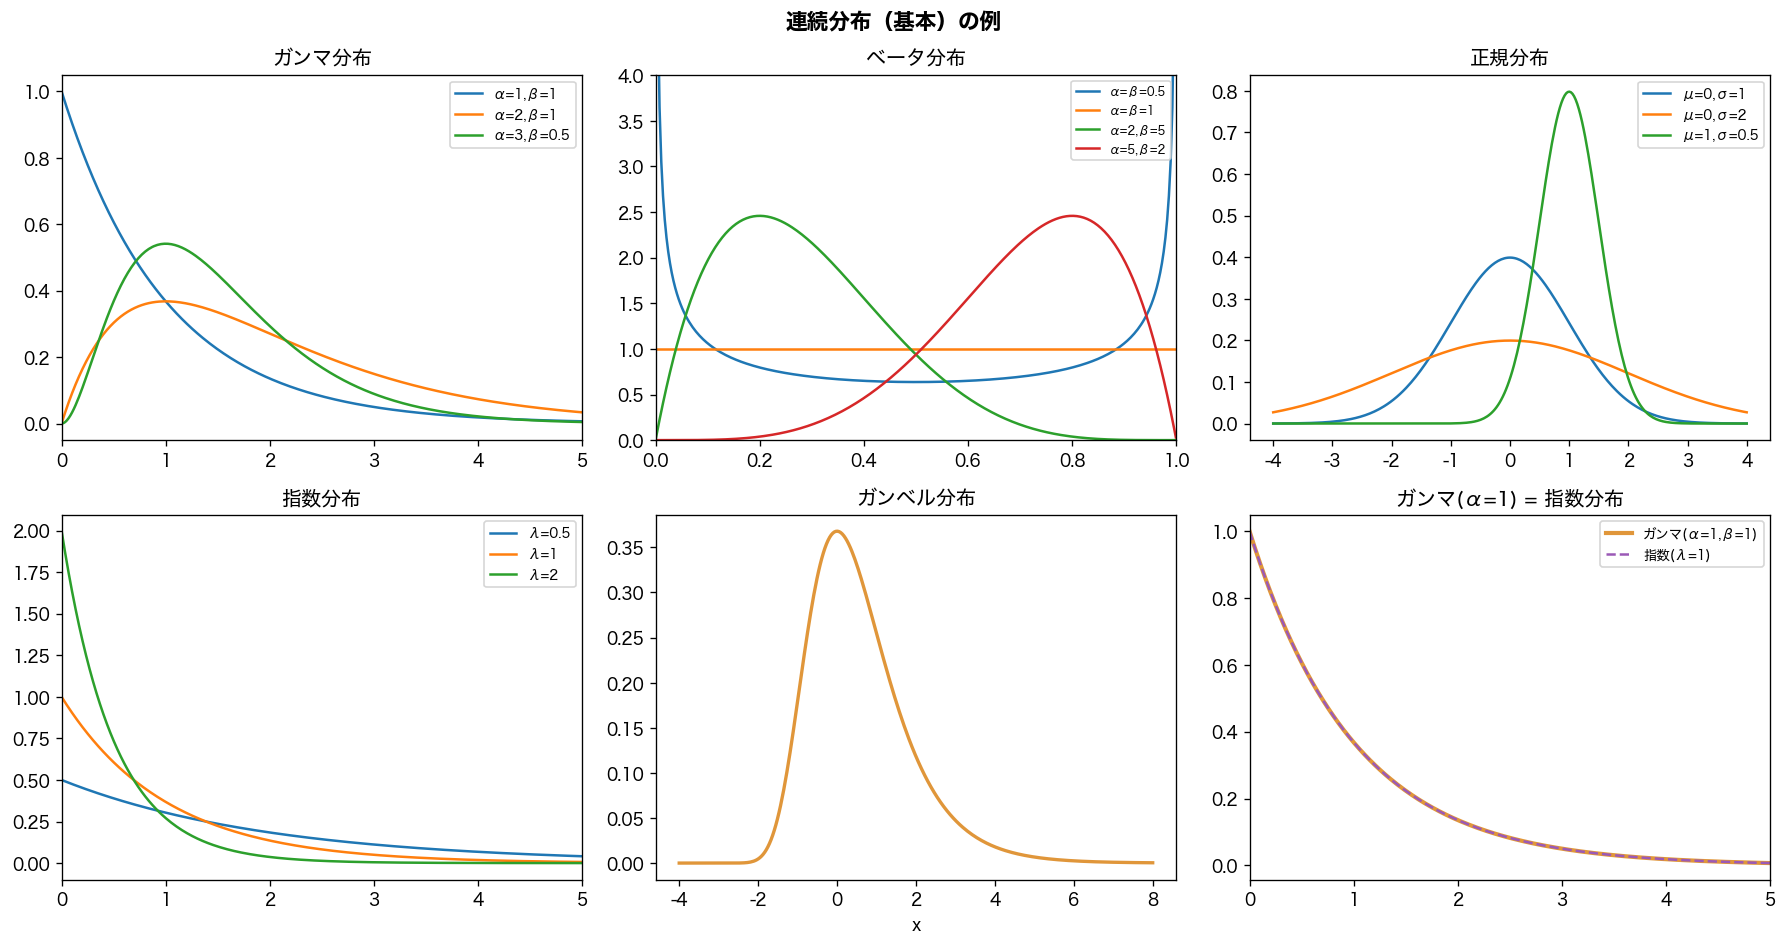

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("連続分布（基本）の例", fontsize=13, fontweight="bold")
x = np.linspace(0.001, 5, 300)

# ガンマ分布
for (a, b), label in [
    ((1, 1), "α=1,β=1"),
    ((2, 1), "α=2,β=1"),
    ((3, 0.5), "α=3,β=0.5"),
]:
    axes[0, 0].plot(x, stats.gamma.pdf(x, a=a, scale=b), label=label)
axes[0, 0].set_title("ガンマ分布")
axes[0, 0].legend(fontsize=8)
axes[0, 0].set_xlim(0, 5)

# ベータ分布
xb = np.linspace(0.001, 0.999, 300)
for (a, b), label in [
    ((0.5, 0.5), "α=β=0.5"),
    ((1, 1), "α=β=1"),
    ((2, 5), "α=2,β=5"),
    ((5, 2), "α=5,β=2"),
]:
    axes[0, 1].plot(xb, stats.beta.pdf(xb, a, b), label=label)
axes[0, 1].set_title("ベータ分布")
axes[0, 1].legend(fontsize=7)
axes[0, 1].set_xlim(0, 1)
axes[0, 1].set_ylim(0, 4)

# 正規分布
xn = np.linspace(-4, 4, 300)
for (mu, sig), label in [
    ((0, 1), "μ=0,σ=1"),
    ((0, 2), "μ=0,σ=2"),
    ((1, 0.5), "μ=1,σ=0.5"),
]:
    axes[0, 2].plot(xn, stats.norm.pdf(xn, mu, sig), label=label)
axes[0, 2].set_title("正規分布")
axes[0, 2].legend(fontsize=8)

# 指数分布
for lam, label in [(0.5, "λ=0.5"), (1, "λ=1"), (2, "λ=2")]:
    axes[1, 0].plot(x, stats.expon.pdf(x, scale=1 / lam), label=label)
axes[1, 0].set_title("指数分布")
axes[1, 0].legend(fontsize=8)
axes[1, 0].set_xlim(0, 5)

# ガンベル分布
xg = np.linspace(-4, 8, 300)
axes[1, 1].plot(xg, stats.gumbel_r.pdf(xg), color="#e0963a", linewidth=2)
axes[1, 1].set_title("ガンベル分布")
axes[1, 1].set_xlabel("x")

# ガンマ vs 指数（alpha=1の特殊ケース）
xe = np.linspace(0, 5, 300)
axes[1, 2].plot(
    xe,
    stats.gamma.pdf(xe, a=1, scale=1),
    label="ガンマ(α=1,β=1)",
    linewidth=2.5,
    color="#e0963a",
)
axes[1, 2].plot(
    xe,
    stats.expon.pdf(xe, scale=1),
    label="指数(λ=1)",
    linewidth=1.5,
    linestyle="--",
    color="#9b59b6",
)
axes[1, 2].set_title("ガンマ(α=1) = 指数分布")
axes[1, 2].legend(fontsize=8)
axes[1, 2].set_xlim(0, 5)

plt.tight_layout()
plt.show()

---
## 3. 混合・複合モデル群 🟢

複数の分布を組み合わせて構成される。顧客の**異質性**（消費者ごとのパラメータのばらつき）を表現するために使われる。


### 3-1. 負の二項分布 (NBD)

**数式**
$$P(k) = \frac{\Gamma(r+k)}{\Gamma(r)k!}p^r (1-p)^k$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $r(1-p)/p$ |
| 分散 $\mathrm{Var}[X]$ | $r(1-p)/p^2$ |
| 過分散比 | $\mathrm{Var}[X]/E[X]=1/p>1$ |
| ポアソンへの収束 | $r\to\infty,\,p\to1,\,r(1-p)/p\to\lambda$ で $\mathrm{Poisson}(\lambda)$ に収束 |

**本書での役割（05, 10章）**
ポアソン-ガンマ混合から導出された購買回数分布。過分散データへの対応。BG/NBD・Pareto/NBDの購買プロセス部分。

**構成**
$$k \mid \lambda \sim \text{Poisson}(\lambda), \quad \lambda \sim \text{Gamma}\left(r, \operatorname{rate}=\frac{p}{1-p}\right)$$

周辺化すると NBD が導出される。


### 3-2. ガンマ・ガンマモデル (GG)

**数式**
$$z_{ij}\mid\nu_i \sim \mathrm{Gamma}(p,\operatorname{rate}=\nu_i), \quad \nu_i \sim \mathrm{Gamma}(q,\operatorname{rate}=\gamma)$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 母集団平均 $E[z_{ij}]$ | $p\gamma/(q-1)\quad(q>1)$ |
| 分散 $\mathrm{Var}[z_{ij}]$ | $p\gamma^2(p+q-1)/[(q-1)^2(q-2)]\quad(q>2)$ |
| 特徴 | 個人内ばらつき + 個人間ばらつきを2層で分解 |

**本書での役割（10章）**
購買金額の個人内ばらつき（$z_{ij}\mid\nu_i$）と個人間ばらつき（$\nu_i$）を2層のガンマ分布で表す。$\gamma$ は `lifetimes` のパラメータ $v$ に対応する。CLV推定の金額モデル部分である。


### 3-3. Beta-Geometric分布 (BG)

**数式**
$$P(T=t) = \frac{B(\alpha+1,\; \beta+t-1)}{B(\alpha,\beta)}$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[T]$ | $\dfrac{\alpha+\beta-1}{\alpha-1}\quad(\alpha>1)$ |
| 導出 | $E[T]=E_\theta[1/\theta]$、$\theta\sim\mathrm{Beta}(\alpha,\beta)$ より |

**本書での役割（10章）**
BG/NBDモデルの離反プロセス部分。幾何分布（離反タイミング）にベータ分布（$\theta_i$ の異質性）を混合。

**構成**
$$T \mid \theta \sim \text{Geometric}(\theta), \quad \theta \sim \text{Beta}(\alpha, \beta)$$


### 3-4. NBDとディリクレ分布を組み合わせたモデル

**数式（構造）**
$$N_i\sim\mathrm{NBD}(M,K),\quad\mathbf{p}_i\sim\mathrm{Dirichlet}(\boldsymbol{\alpha}),\quad\mathbf{X}_i\mid N_i,\mathbf{p}_i\sim\mathrm{Multinomial}(N_i,\mathbf{p}_i)$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| カテゴリー購買回数の平均 | $E[N_i]=M$ |
| ブランド別購買回数の平均 | $E[X_{ij}]=M\alpha_j/\alpha_0$ |
| 重複購買率 | ディリクレ分布のパラメータ $\alpha_i$ から解析的に導出可能 |

**本書での役割（05章）**
ブランド選択確率の異質性（ディリクレ分布）と購買回数の過分散（NBD）を組み合わせたモデル。ブランド間の市場占有率・重複購買率の記述に使用。


### 3-5. 混合ガウスモデル (GMM)

**数式**
$$f(\mathbf{x}) = \sum_k \pi_k \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \Sigma_k), \qquad \pi_k\ge0,\quad\sum_k\pi_k=1$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[\mathbf{X}]$ | $\bar{\boldsymbol{\mu}}=\sum_k\pi_k\boldsymbol{\mu}_k$ |
| 共分散 $\operatorname{Cov}(\mathbf{X})$ | $\sum_k\pi_k\left[\Sigma_k+(\boldsymbol{\mu}_k-\bar{\boldsymbol{\mu}})(\boldsymbol{\mu}_k-\bar{\boldsymbol{\mu}})^\top\right]$ |
| エントロピー | 一般に解析的閉形式なし（数値積分で計算）|

**本書での役割（02章）**
GMMによる顧客セグメンテーション。複数のガウス分布の混合でクラスタを表現。EMアルゴリズムで推定。


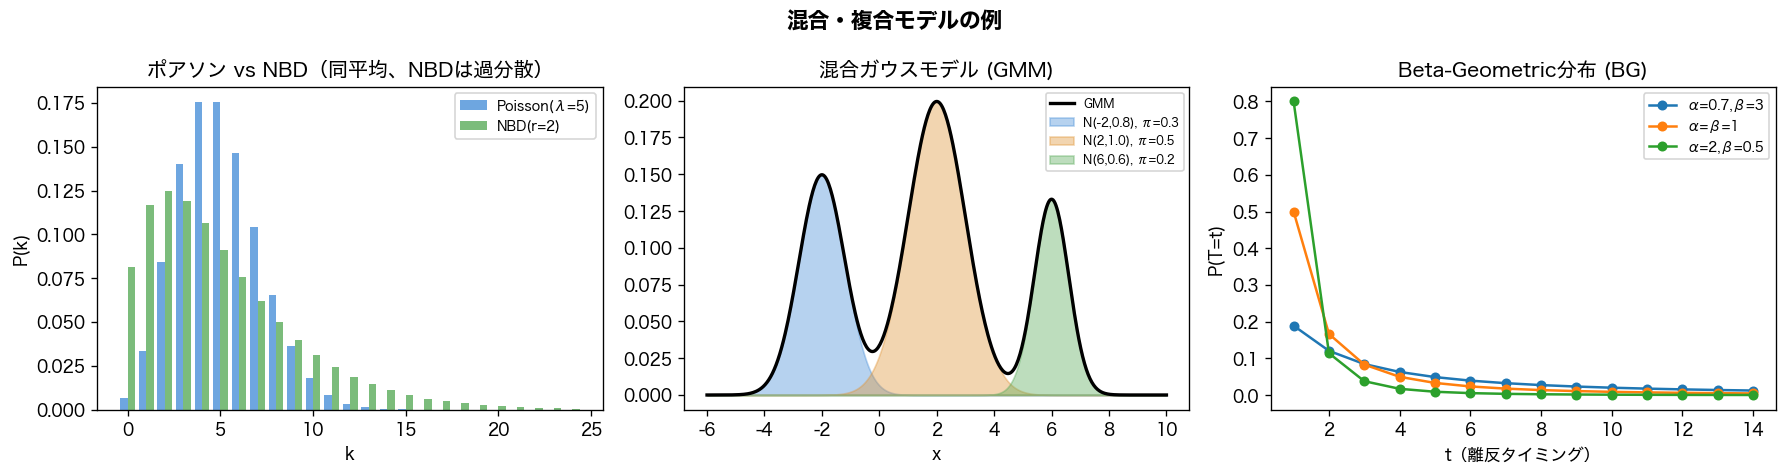

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("混合・複合モデルの例", fontsize=13, fontweight="bold")

# NBD: ポアソン vs NBD（過分散の比較）
k = np.arange(0, 25)
lam_p = 5
axes[0].bar(
    k - 0.2,
    stats.poisson.pmf(k, lam_p),
    width=0.4,
    label=f"Poisson(λ={lam_p})",
    color="#4a90d9",
    alpha=0.8,
)
r_nbd, p_nbd = 2, 2 / 7
axes[0].bar(
    k + 0.2,
    stats.nbinom.pmf(k, r_nbd, p_nbd),
    width=0.4,
    label=f"NBD(r={r_nbd})",
    color="#5aab5a",
    alpha=0.8,
)
axes[0].set_title("ポアソン vs NBD（同平均、NBDは過分散）")
axes[0].legend(fontsize=8)
axes[0].set_xlabel("k")
axes[0].set_ylabel("P(k)")

# GMM
xg = np.linspace(-6, 10, 500)
params = [(0.3, -2, 0.8), (0.5, 2, 1.0), (0.2, 6, 0.6)]
gmm = sum(pi * stats.norm.pdf(xg, mu, sig) for pi, mu, sig in params)
axes[1].plot(xg, gmm, "k-", linewidth=2, label="GMM")
colors = ["#4a90d9", "#e0963a", "#5aab5a"]
for (pi, mu, sig), c in zip(params, colors):
    axes[1].fill_between(
        xg,
        pi * stats.norm.pdf(xg, mu, sig),
        alpha=0.4,
        color=c,
        label=f"N({mu},{sig}), π={pi}",
    )
axes[1].set_title("混合ガウスモデル (GMM)")
axes[1].legend(fontsize=7)
axes[1].set_xlabel("x")

# BG分布
t = np.arange(1, 15)
from scipy.special import betaln


def bg_pmf(t, alpha, beta):
    return np.exp(betaln(alpha + 1, beta + t - 1) - betaln(alpha, beta))


for (a, b), label in [
    ((0.7, 3.0), "α=0.7,β=3"),
    ((1.0, 1.0), "α=β=1"),
    ((2.0, 0.5), "α=2,β=0.5"),
]:
    axes[2].plot(t, bg_pmf(t, a, b), "o-", label=label, markersize=5)
axes[2].set_title("Beta-Geometric分布 (BG)")
axes[2].set_xlabel("t（離反タイミング）")
axes[2].set_ylabel("P(T=t)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## 4. 派生・特殊分布群 🟣

主に**変換・極限・特殊ケース**によって他の分布から導かれる。


### 4-1. 多変量正規分布

**数式**
$$f(\mathbf{x}) \propto \exp\!\left(-\frac{1}{2}(\mathbf{x}-\boldsymbol{\mu})^\top \Sigma^{-1}(\mathbf{x}-\boldsymbol{\mu})\right)$$

**統計量**（次元 $d$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[\mathbf{X}]$ | $\boldsymbol{\mu}$ |
| 分散共分散行列 | $\Sigma$ |
| 微分エントロピー | $\tfrac{1}{2}\ln\bigl[(2\pi e)^d|\Sigma|\bigr]$ |
| **最大エントロピー性** | 同じ平均・共分散をもつ連続分布の中で最大エントロピー |

**本書での役割（04章）**
多項プロビット（MNP）モデルにおける誤差項ベクトル $(\varepsilon_{i1},\ldots,\varepsilon_{iJ})$ の分布。IIA制約からの解放。

**他の分布との関係**
- ← **正規分布**：1次元→多次元拡張
- → **GMM**：複数混合してGMMを構成


### 4-2. ロジスティック分布

**数式**
$$f(x) = \frac{e^x}{(1+e^x)^2}$$

**統計量**（位置 $\mu$、スケール $s$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $\mu$ |
| 分散 $\mathrm{Var}[X]$ | $\pi^2 s^2/3$ |
| 最頻値・中央値 | $\mu$ |
| 微分エントロピー | $\ln s+2$ |
| 標準型 $(\mu=0,s=1)$ | 平均 $0$、分散 $\pi^2/3\approx3.29$ |

**本書での役割（04章）**
ガンベル分布の差として導出。ロジットモデルの選択確率の積分を可能にする（ガンベル分布の帰結として登場）。

**他の分布との関係**
- ← **ガンベル分布**：2つの独立なガンベル確率変数の差


### 4-3. ワイブル分布

**数式**
$$f(x) = \frac{k}{\lambda}\left(\frac{x}{\lambda}\right)^{k-1} e^{-(x/\lambda)^k}$$

**統計量**（形状 $k$、スケール $\lambda$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $\lambda\,\Gamma\!\left(1+\dfrac{1}{k}\right)$ |
| 分散 $\mathrm{Var}[X]$ | $\lambda^2\!\left[\Gamma\!\left(1+\dfrac{2}{k}\right)-\Gamma\!\left(1+\dfrac{1}{k}\right)^2\right]$ |
| 最頻値 | $\lambda\!\left(\dfrac{k-1}{k}\right)^{1/k}\quad(k>1)$ |
| $k=1$ | 指数分布 $\mathrm{Exp}(1/\lambda)$ と一致 |

**本書での役割（07章）**
生存時間解析においてパラメトリック推定で仮定しうる分布形の例として言及（カプラン・マイヤーのノンパラメトリック性との対比）。

**他の分布との関係**
- ← **指数分布**：$k=1$の特殊ケース


### 4-4. カイ二乗分布

**数式**
$$f(x) \propto x^{k/2-1}e^{-x/2}, \quad x > 0$$

**統計量**（自由度 $k$）

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $k$ |
| 分散 $\mathrm{Var}[X]$ | $2k$ |
| 最頻値 | $\max(k-2,\,0)$ |
| ガンマとの関係 | $\chi^2(k)=\mathrm{Gamma}(\alpha=k/2,\,\beta=2)$ |

**本書での役割（07章）**
ログランク検定の検定統計量の漸近分布（生存曲線の群間差の有意性検定）。

**他の分布との関係**
- ← **正規分布**：$Z_1,\ldots,Z_k \overset{iid}{\sim} N(0,1)$ のとき $\sum Z_i^2 \sim \chi^2(k)$


### 4-5. 対数正規分布（参考）

**数式**
$$f(x)=\frac{1}{x\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(\ln x-\mu)^2}{2\sigma^2}\right],\quad x>0$$

**統計量**

| 統計量 | 値 |
|:---|:---|
| 平均 $E[X]$ | $e^{\mu+\sigma^2/2}$ |
| 分散 $\mathrm{Var}[X]$ | $(e^{\sigma^2}-1)\,e^{2\mu+\sigma^2}$ |
| 中央値 | $e^\mu$ |
| 最頻値 | $e^{\mu-\sigma^2}$ |
| 微分エントロピー | $\mu+\tfrac{1}{2}\ln(2\pi e\sigma^2)$ |

**本書での位置づけ**
本書本文では使用していない。正規変数の指数変換として、分布間の関係を示す参考のために掲載する。

**他の分布との関係**
- ← **正規分布**：$X\sim N(\mu,\sigma^2)$ のとき $e^X$ は対数正規分布に従う


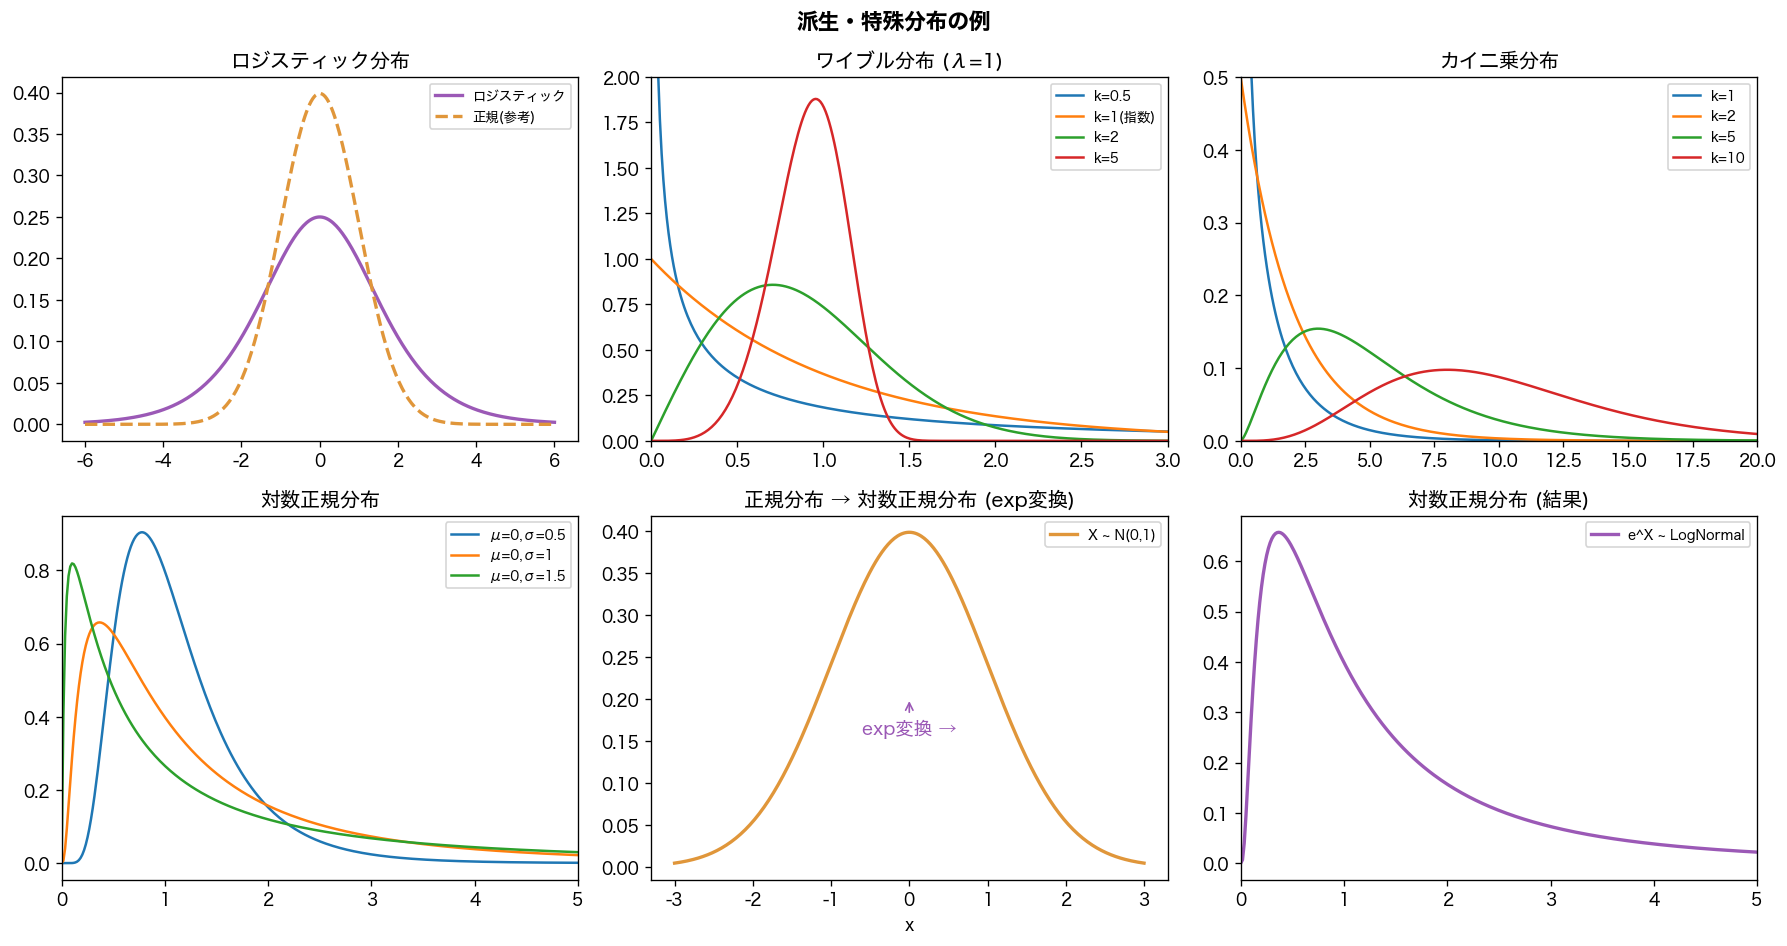

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
fig.suptitle("派生・特殊分布の例", fontsize=13, fontweight="bold")

# ロジスティック分布
xl = np.linspace(-6, 6, 300)
axes[0, 0].plot(
    xl,
    stats.logistic.pdf(xl),
    color="#9b59b6",
    linewidth=2,
    label="ロジスティック",
)
axes[0, 0].plot(
    xl,
    stats.norm.pdf(xl),
    color="#e0963a",
    linewidth=2,
    linestyle="--",
    label="正規(参考)",
)
axes[0, 0].set_title("ロジスティック分布")
axes[0, 0].legend(fontsize=8)

# ワイブル分布
xw = np.linspace(0.001, 3, 300)
for k_w, label in [(0.5, "k=0.5"), (1, "k=1(指数)"), (2, "k=2"), (5, "k=5")]:
    axes[0, 1].plot(xw, stats.weibull_min.pdf(xw, k_w), label=label)
axes[0, 1].set_title("ワイブル分布 (λ=1)")
axes[0, 1].legend(fontsize=8)
axes[0, 1].set_xlim(0, 3)
axes[0, 1].set_ylim(0, 2)

# カイ二乗分布
xc = np.linspace(0.01, 20, 300)
for df, label in [(1, "k=1"), (2, "k=2"), (5, "k=5"), (10, "k=10")]:
    axes[0, 2].plot(xc, stats.chi2.pdf(xc, df), label=label)
axes[0, 2].set_title("カイ二乗分布")
axes[0, 2].legend(fontsize=8)
axes[0, 2].set_xlim(0, 20)
axes[0, 2].set_ylim(0, 0.5)

# 対数正規分布
xln = np.linspace(0.001, 5, 300)
for (mu, sig), label in [
    ((0, 0.5), "μ=0,σ=0.5"),
    ((0, 1), "μ=0,σ=1"),
    ((0, 1.5), "μ=0,σ=1.5"),
]:
    axes[1, 0].plot(
        xln, stats.lognorm.pdf(xln, s=sig, scale=np.exp(mu)), label=label
    )
axes[1, 0].set_title("対数正規分布")
axes[1, 0].legend(fontsize=8)
axes[1, 0].set_xlim(0, 5)

# 正規 → 対数正規の変換イメージ
xn2 = np.linspace(-3, 3, 300)
ax_r = axes[1, 1]
ax_r.plot(
    xn2, stats.norm.pdf(xn2), color="#e0963a", linewidth=2, label="X ~ N(0,1)"
)
ax_r.set_title("正規分布 → 対数正規分布 (exp変換)")
ax_r.legend(fontsize=8)
ax_r.set_xlabel("x")
ax_r.annotate(
    "exp変換 →",
    xy=(0.5, 0.5),
    xycoords="axes fraction",
    fontsize=11,
    ha="center",
    color="#9b59b6",
    arrowprops={"arrowstyle": "->", "color": "#9b59b6"},
    xytext=(0.5, 0.4),
)

xln2 = np.linspace(0.001, 5, 300)
axes[1, 2].plot(
    xln2,
    stats.lognorm.pdf(xln2, s=1),
    color="#9b59b6",
    linewidth=2,
    label="e^X ~ LogNormal",
)
axes[1, 2].set_title("対数正規分布 (結果)")
axes[1, 2].legend(fontsize=8)
axes[1, 2].set_xlim(0, 5)

plt.tight_layout()
plt.show()

---
## 5. 分布間の関係まとめ

### 5-1. 購買モデルの中心的な流れ（05, 10章）

```
λ ~ ガンマ分布（個人間異質性）
             ↓ 条件付き購買数 X|λ ~ ポアソン分布
             ↓ λ を周辺化
          負の二項分布 (NBD)
                                          │
                              ディリクレ分布 と組み合わせ
                                          ▼
                     NBDとディリクレ分布を組み合わせたモデル
```

### 5-2. CLV推定モデル（10章）

```
【購買プロセス】          【離反プロセス】
ポアソン(λ)               ベルヌーイ/幾何(θ)
  ↑ ガンマ混合              ↑ ベータ混合
  NBD                       BG分布
  ↓ 組み合わせ
  BG/NBDモデル
  ↓
【購買金額】
ガンマ・ガンマモデル (GG)
  ↓ CLV = E[購買回数] × E[1回あたり購買金額]
```

### 5-3. 選択モデルの流れ（04章）

```
カテゴリ分布
  ├── ガンベル分布（誤差項仮定） ──► ロジスティック分布 ──► ロジットモデル
  └── 多変量正規分布（誤差項仮定）──────────────────────► MNPモデル
  ← ディリクレ分布（選択確率の個人間混合）
```

### 5-4. 生存時間解析の流れ（07章）

```
指数分布 ──形状パラメータ追加──► ワイブル分布
                     ↑
             ガンマ分布(α=1の特殊ケース)
正規分布 ──N(0,1)²の和──► カイ二乗分布（ログランク検定）
```


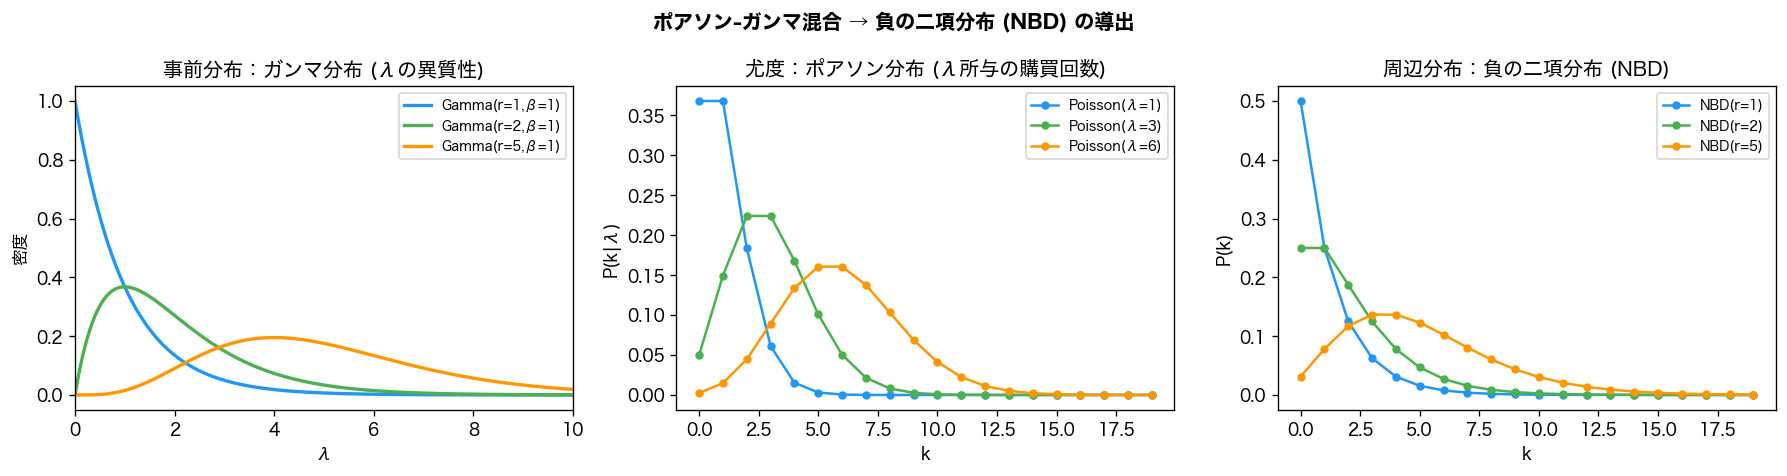

In [6]:
# 共役事前分布の関係を可視化
# ポアソン-ガンマ混合 → NBD の導出デモ

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(
    "ポアソン-ガンマ混合 → 負の二項分布 (NBD) の導出",
    fontsize=12,
    fontweight="bold",
)

k = np.arange(0, 20)
r_vals = [1, 2, 5]
colors_nbd = ["#2196F3", "#4CAF50", "#FF9800"]

# ガンマ事前分布
x_g = np.linspace(0, 10, 300)
for r, c in zip(r_vals, colors_nbd):
    beta_val = 1.0
    axes[0].plot(
        x_g,
        stats.gamma.pdf(x_g, a=r, scale=beta_val),
        color=c,
        label=f"Gamma(r={r},β=1)",
        linewidth=2,
    )
axes[0].set_title("事前分布：ガンマ分布 (λの異質性)")
axes[0].set_xlabel("λ")
axes[0].set_ylabel("密度")
axes[0].legend(fontsize=8)
axes[0].set_xlim(0, 10)

# 条件付き分布（ポアソン）
lam_examples = [1, 3, 6]
for lam, c in zip(lam_examples, colors_nbd):
    axes[1].plot(
        k,
        stats.poisson.pmf(k, lam),
        "o-",
        color=c,
        label=f"Poisson(λ={lam})",
        markersize=4,
    )
axes[1].set_title("尤度：ポアソン分布 (λ所与の購買回数)")
axes[1].set_xlabel("k")
axes[1].set_ylabel("P(k|λ)")
axes[1].legend(fontsize=8)

# 周辺分布（NBD）
for r, c in zip(r_vals, colors_nbd):
    p_val = 0.5
    axes[2].plot(
        k,
        stats.nbinom.pmf(k, r, p_val),
        "o-",
        color=c,
        label=f"NBD(r={r})",
        markersize=4,
    )
axes[2].set_title("周辺分布：負の二項分布 (NBD)")
axes[2].set_xlabel("k")
axes[2].set_ylabel("P(k)")
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## 6. 参考：二項分布 → ポアソン分布の極限

$n \to \infty,\; p \to 0,\; np = \lambda$ (一定) のとき、二項分布はポアソン分布に収束する（関係図の**破線**はこの近似関係を示す）。


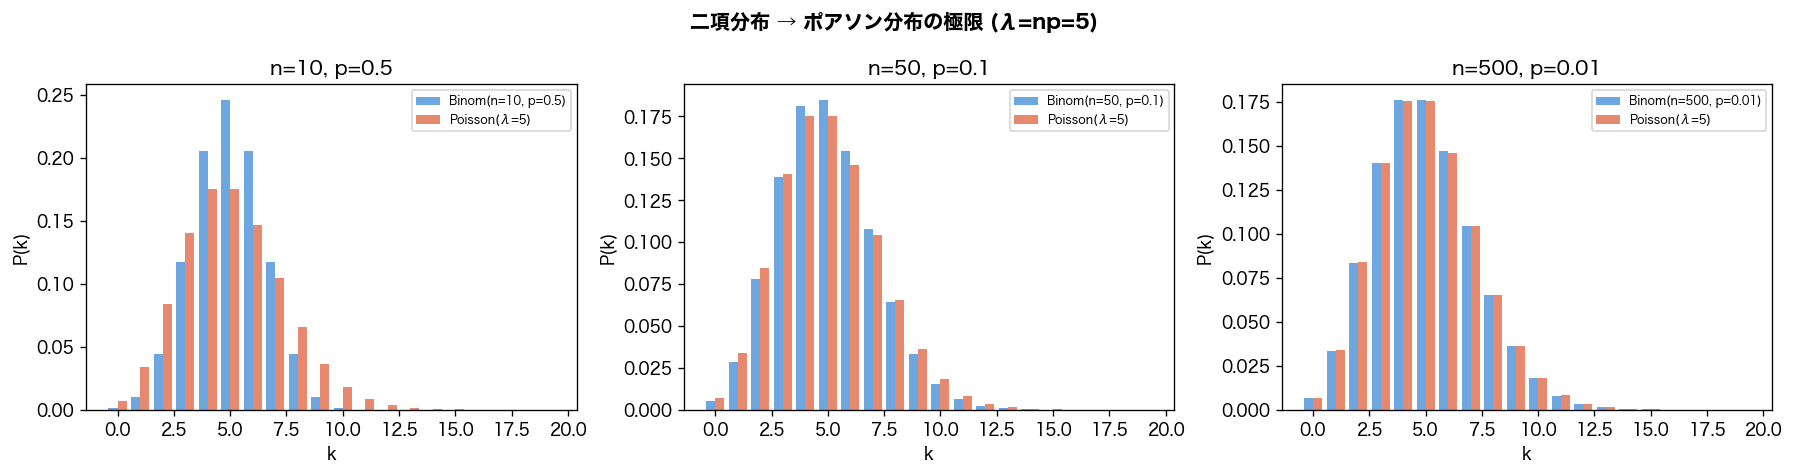

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle(
    "二項分布 → ポアソン分布の極限 (λ=np=5)", fontsize=12, fontweight="bold"
)

lam = 5
configs = [(10, 0.5), (50, 0.1), (500, 0.01)]

for ax, (n, p) in zip(axes, configs):
    k_range = np.arange(0, 20)
    ax.bar(
        k_range - 0.2,
        stats.binom.pmf(k_range, n, p),
        width=0.4,
        label=f"Binom(n={n}, p={p})",
        color="#4a90d9",
        alpha=0.8,
    )
    ax.bar(
        k_range + 0.2,
        stats.poisson.pmf(k_range, lam),
        width=0.4,
        label=f"Poisson(λ={lam})",
        color="#e06c4a",
        alpha=0.8,
    )
    ax.set_title(f"n={n}, p={p}")
    ax.set_xlabel("k")
    ax.set_ylabel("P(k)")
    ax.legend(fontsize=7)

plt.tight_layout()
plt.show()